# EMQA_L5_shape

**Load and solar profile factors, Romania**

Energy Markets Quantitative Analysis (EMQA), Lecture 5 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L5/EMQA_L5_shape/EMQA_L5_shape.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Profile factors: what one MWh of load or of solar output is worth relative to one MWh of the band.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5,
    'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
# fixed colour per entity (course palette)
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}


def legend_bottom(fig, handles=None, labels=None, ncol=4):
    """Legend centred under the axes, outside the plotting area."""
    if handles is None:
        handles, labels = [], []
        for ax in fig.axes:
            for h, l in zip(*ax.get_legend_handles_labels()):
                if l not in labels:
                    handles.append(h)
                    labels.append(l)
    fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0),
               frameon=False, handlelength=2.0, columnspacing=1.2)


def legend_compact(fig, ncol):
    """Bottom legend with shorter handles and column gaps, for many short entries."""
    legend_bottom(fig, ncol=ncol)
    h, l = fig.legends[-1].legend_handles, [t.get_text() for t in fig.legends[-1].get_texts()]
    fig.legends[-1].remove()
    fig.legend(h, l, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, 0.0), frameon=False,
               handlelength=1.0, handletextpad=0.4, columnspacing=0.9)


def save_chart(fig, name):
    """Keep under the axes exactly the height of the bottom legend, then save the PNG."""
    fig.canvas.draw()
    bottom = max([lg.get_window_extent().height / fig.bbox.height + 0.035 for lg in fig.legends] or [0.0])
    fig.tight_layout(rect=(0, bottom, 1, 1))
    plt.savefig(name + '.png', dpi=150, bbox_inches='tight', transparent=True)
    plt.show()


def show(label, value, key=None, fmt='.2f'):
    """Print one number of the slide; [key] = its name in lectures/L5/L5_numbers.json."""
    s = value if isinstance(value, str) else format(value, fmt)
    print(f'{label:<58s} {s:>12s}' + (f'   [{key}]' if key else ''))

In [3]:
# daily day-ahead base prices (mean of all market time units of the CET/CEST day), EUR/MWh
PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
# cut-off = last complete month of the Romanian series
_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
d = lambda ts: pd.Timestamp(ts).strftime('%Y-%m-%d')
print('cut-off (last complete month):', d(END))

cut-off (last complete month): 2026-10-31


In [4]:
PH = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc'],
                 usecols=['timestamp_utc', 'RO']).set_index('timestamp_utc')
GH = pd.read_csv(DATA + 'generation_ro_mw_hourly_utc.csv', parse_dates=['timestamp_utc'],
                 usecols=['timestamp_utc', 'load', 'solar']).set_index('timestamp_utc')
J = pd.concat([PH['RO'], GH['load'], GH['solar']], axis=1).loc[:str(END.date()) + ' 21:00'].dropna()
J = J[J.index >= '2015-01-05']
J['y'] = J.index.tz_convert('Europe/Brussels').year


def profile_factor(g):
    base = g['RO'].mean()
    return pd.Series({'base': base, 'load_w': (g['RO'] * g['load']).sum() / g['load'].sum(),
                      'solar_w': (g['RO'] * g['solar']).sum() / g['solar'].sum() if g['solar'].sum() > 0 else np.nan})


PF = J.groupby('y').apply(profile_factor)
PF['f_load'] = PF['load_w'] / PF['base']
PF['f_solar'] = PF['solar_w'] / PF['base']
show('hours used', len(J), 'shape.n_hours', ',d')
for y in PF.index:
    show(f'{y}: load factor', PF.loc[y, 'f_load'], f'shape.f_load.{y}', '.3f')
    show(f'{y}: solar factor', PF.loc[y, 'f_solar'], f'shape.f_solar.{y}', '.3f')
show('lowest solar factor', PF['f_solar'].min(), 'shape.solar_min', '.3f')
show('  year', str(PF['f_solar'].idxmin()), 'shape.solar_min_y')
show('2025: load-weighted minus baseload price, EUR/MWh', PF.loc[2025, 'load_w'] - PF.loc[2025, 'base'], 'shape.load_prem.2025', '.2f')

hours used                                                      103,343   [shape.n_hours]
2015: load factor                                                 1.034   [shape.f_load.2015]
2015: solar factor                                                1.086   [shape.f_solar.2015]
2016: load factor                                                 1.039   [shape.f_load.2016]
2016: solar factor                                                1.009   [shape.f_solar.2016]
2017: load factor                                                 1.052   [shape.f_load.2017]
2017: solar factor                                                1.095   [shape.f_solar.2017]
2018: load factor                                                 1.036   [shape.f_load.2018]
2018: solar factor                                                1.049   [shape.f_solar.2018]
2019: load factor                                                 1.039   [shape.f_load.2019]
2019: solar factor                                          

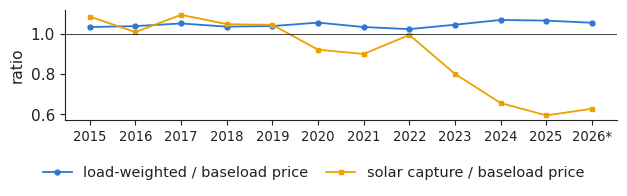

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 2.0))
ax.plot(PF.index, PF['f_load'], marker='o', ms=3.5, color=PAL['RO'], lw=1.3, label='load-weighted / baseload price')
ax.plot(PF.index, PF['f_solar'], marker='s', ms=3.5, color=PAL['BG'], lw=1.3, label='solar capture / baseload price')
ax.axhline(1, color='#222222', lw=0.6)
ax.set_xticks(PF.index)
ax.set_xticklabels([str(y) + ('*' if y == END.year else '') for y in PF.index], fontsize=9.5)    # * = to the cut-off
ax.set_ylabel('ratio')
legend_bottom(fig, ncol=2)
save_chart(fig, 'shape')